# Diabetes Prediction System
## An End-to-End Machine Learning Classification Project
#### **Name:** Sonjor Ahmed

#### **Project Type:** Individual Project

#### **Dataset:** CDC Diabetes Health Indicators (BRFSS 2015)

#### **Dataset Size:** 253,680 Survey Records

#### **Input Features:** 21

#### **Task:** Binary Classification

#### **Course:** Shohojcoding MLB Batch-2

#### **Instructor:** Md. Mahabub Hasan Mamun

In [132]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sonjorahmed/diabetes-binary-health-indicators-brfss2015/diabetes_binary_health_indicators_BRFSS2015.csv


# Phase 1 — Setup & First Look

In [96]:
df= pd.read_csv("/kaggle/input/datasets/sonjorahmed/diabetes-binary-health-indicators-brfss2015/diabetes_binary_health_indicators_BRFSS2015.csv")
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [97]:
print(df.isnull().sum())
print("\n\nSHape: ", df.shape)

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


SHape:  (253680, 22)


In [98]:
print(df.columns.tolist())
print("\n")
print("Info :",  df.info())

['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 n

In [99]:
df.describe()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.139333,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.346294,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [100]:
df.duplicated().sum()

np.int64(24206)

In [101]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [102]:
target= "Diabetes_binary"
numeric = ["BMI", "MentHlth", "PhysHlth"]
ordinal= ["GenHlth", "Age", "Education", "Income"]
binary= [c for c in df.columns if c not in numeric + ordinal + [target]]

In [103]:
df[numeric].value_counts()

BMI   MentHlth  PhysHlth
27.0  0.0       0.0         13100
26.0  0.0       0.0         11186
24.0  0.0       0.0         10842
25.0  0.0       0.0          9343
28.0  0.0       0.0          8752
                            ...  
92.0  5.0       30.0            1
      10.0      0.0             1
      15.0      3.0             1
      30.0      30.0            1
12.0  30.0      30.0            1
Name: count, Length: 9366, dtype: int64

In [104]:
df[target].value_counts(normalize=True) *100

Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64

# Phase 2 — Exploratory Data Analysis (EDA)

In [105]:
import seaborn as sns
from matplotlib import pyplot as plt
counts = df[target].value_counts().sort_index()
counts

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

##### (a) Binary target distribution.

/tmp/ipykernel_50/2062539970.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["No diabetes (0)", "Prediabetes/diabetes (1)"], y=counts.values, palette=["r", "g"])


Text(0, 0.5, 'Number of People')

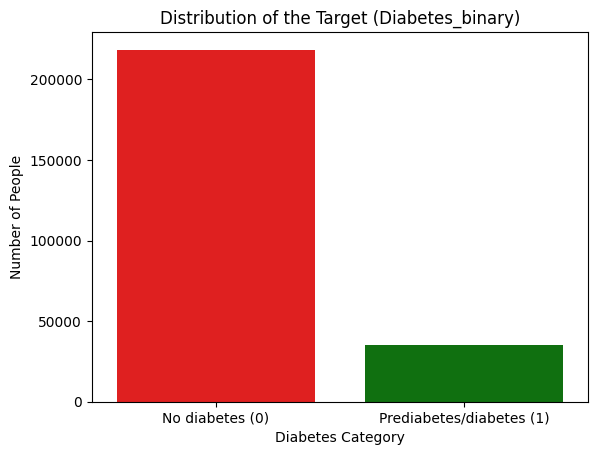

In [106]:
sns.barplot(x=["No diabetes (0)", "Prediabetes/diabetes (1)"], y=counts.values, palette=["r", "g"])
plt.title("Distribution of the Target (Diabetes_binary)")
plt.xlabel("Diabetes Category")
plt.ylabel("Number of People")

In [107]:
print("Class percentages:")
display((df[target].value_counts(normalize=True).sort_index() * 100).rename("percentage").round(2).to_frame())

Class percentages:


,percentage
Diabetes_binary,
0.0,86.07
1.0,13.93


##### (b) BMI histogram

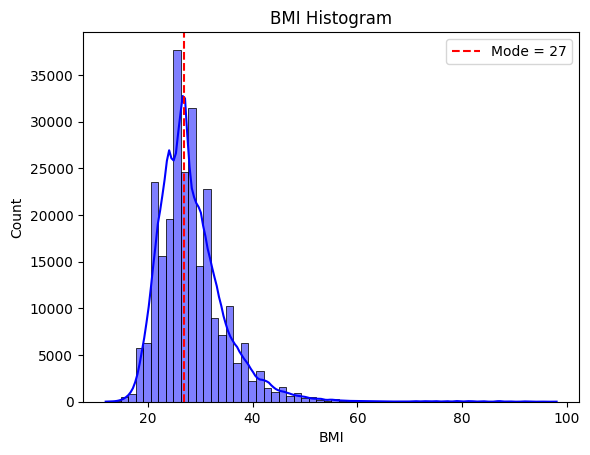

In [108]:
bmi_mode = df["BMI"].mode()[0]
sns.histplot(data= df, x=df["BMI"], bins= 60, kde= True, color="blue")
plt.axvline(bmi_mode, color="r", linestyle="--", label=f"Mode = {bmi_mode:.0f}")
plt.title("BMI Histogram")
plt.xlabel("BMI")
plt.ylabel("Count")
plt.legend()
plt.show()

##### (c) Diabetes rate across Age groups.

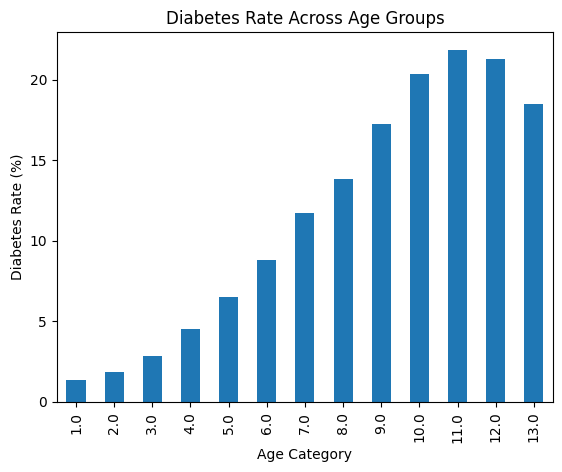

In [109]:
age_rate=  df.groupby("Age")["Diabetes_binary"].mean()*100
age_rate.plot(kind="bar")
plt.title("Diabetes Rate Across Age Groups")
plt.xlabel("Age Category")
plt.ylabel("Diabetes Rate (%)")
plt.show()

In [110]:
display(age_rate.rename("class_1_rate_percent").round(2).to_frame().head())

,class_1_rate_percent
Age,
1.0,1.37
2.0,1.84
3.0,2.82
4.0,4.53
5.0,6.50


##### (d) Diabetes rate by GenHlth or HighBP

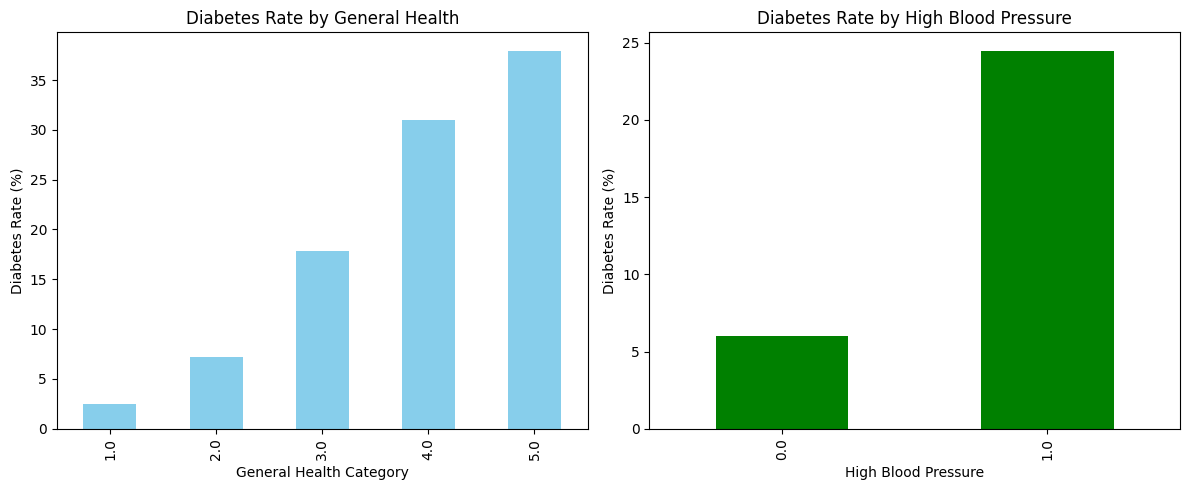

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

health_rate = df.groupby("GenHlth")["Diabetes_binary"].mean() * 100
health_rate.plot(kind="bar", color="skyblue", ax=axes[0])
axes[0].set_title("Diabetes Rate by General Health")
axes[0].set_xlabel("General Health Category")
axes[0].set_ylabel("Diabetes Rate (%)")

highbp_rate = df.groupby("HighBP")["Diabetes_binary"].mean() * 100
highbp_rate.plot(kind="bar", color="green", ax=axes[1])
axes[1].set_title("Diabetes Rate by High Blood Pressure")
axes[1].set_xlabel("High Blood Pressure")
axes[1].set_ylabel("Diabetes Rate (%)")

plt.tight_layout()
plt.show()

In [112]:
display(health_rate.rename("class_1_rate_percent").round(2).to_frame())

,class_1_rate_percent
GenHlth,
1.0,2.52
2.0,7.16
3.0,17.79
4.0,31.01
5.0,37.89


##### (e) A correlation heatmap of selected numeric features, or a boxplot of BMI by target.

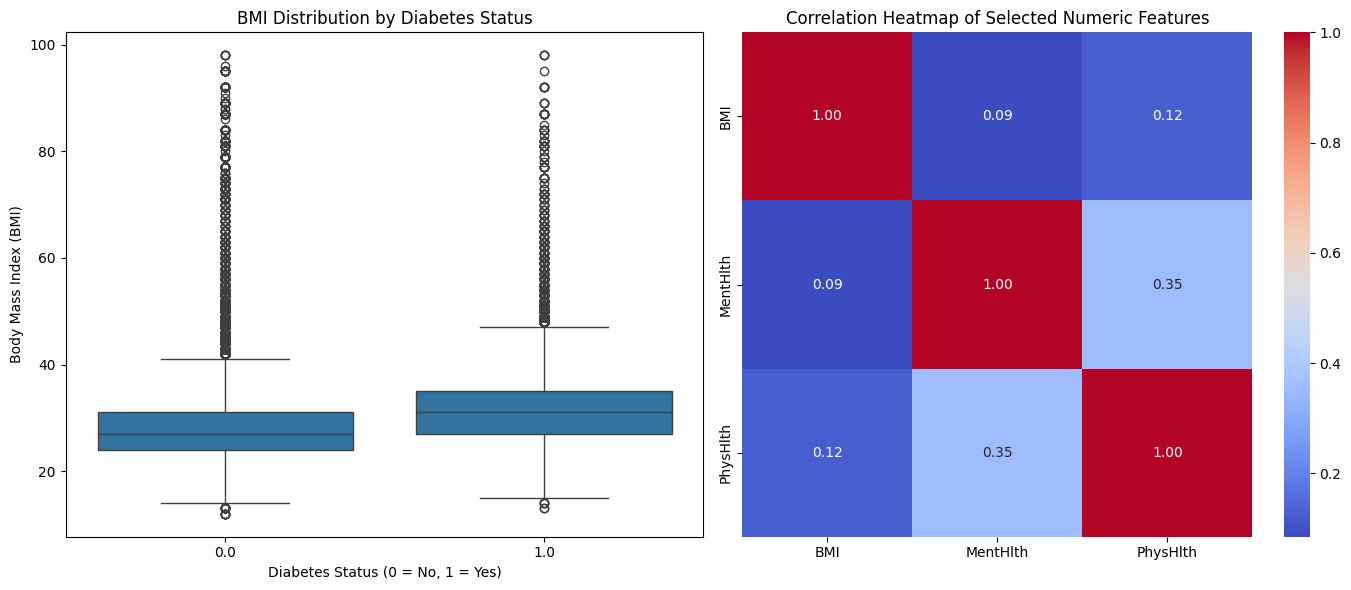

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(data=df, x=target, y="BMI", ax=axes[0])
axes[0].set_title("BMI Distribution by Diabetes Status")
axes[0].set_xlabel("Diabetes Status (0 = No, 1 = Yes)")
axes[0].set_ylabel("Body Mass Index (BMI)")

selected_cols = numeric
sns.heatmap(df[selected_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation Heatmap of Selected Numeric Features")
plt.tight_layout()
plt.show()

In [114]:
bmi_summary = df.groupby(target)["BMI"].agg(["mean", "median", "std"]).round(2)
bmi_summary

,mean,median,std
Diabetes_binary,,,
0.0,27.81,27.0,6.29
1.0,31.94,31.0,7.36


In [115]:
highbp_rate = df.groupby("HighBP")[target].agg(["mean", "count"])
highbp_rate["class_1_rate_percent"] = highbp_rate["mean"] * 100
highbp_rate = highbp_rate.drop(columns="mean").round(2)
display(highbp_rate)

,count,class_1_rate_percent
HighBP,,
0.0,144851,6.04
1.0,108829,24.45


# Phase 3 — Train/Test Split & Preprocessing

In [116]:
X = df.drop(columns=target)
y = df[target]
print("X =", X.shape)
print("\ny =", y.shape)

X = (253680, 21)

y = (253680,)


In [117]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=46)
print("X_train = ", X_train.shape)
print("X_test = ", X_test.shape)

X_train =  (202944, 21)
X_test =  (50736, 21)


In [118]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline= Pipeline(steps=[
     ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler()),
])
binary_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
])

In [119]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric),
        ("ordinal", ordinal_pipeline, ordinal),
        ("binary", binary_pipeline, binary),
    ],
    remainder="drop",
)
preprocessor

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('scaler', StandardScaler())]),
                                 ['BMI', 'MentHlth', 'PhysHlth']),
                                ('ordinal',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('scaler', StandardScaler())]),
                                 ['GenHlth', 'Age', 'Education', 'Income']),
                                ('binary',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent'))]),
                                 ['HighBP', 'HighChol', 'CholCheck', 'Smoker',
                                  'Stroke', 'HeartDiseaseorAttack',
                                  'PhysActivity', 'Fruits', 'Veggies',
                                  'HvyAlcoholConsump', 'AnyHealthcare',
                                  'NoDocbcCost', 'DiffWalk', 'Sex'])])

# Phase 4 — Model Training

In [120]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=46),
    "Linear SVM": LinearSVC(class_weight="balanced",max_iter=5000,dual=False,random_state=46,),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=46, n_jobs=-1),
}
validation_pipelines = {}
for name, model in models.items():
  full_pipeline = Pipeline(steps=[
      ("preprocessor", preprocessor), 
      ("classifier", model)
    ])
full_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('ordinal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['GenHlth', 'Age',
                                                   'Education', 'Income']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke',
                                                   'HeartDiseaseorAttack',
                                                   'PhysActivity', 'Fruits',
                                                   'Veggies',
                                                   'HvyAlcoholConsump',
                                                   'AnyHealthcare',
                                                   'NoDocbcCost', 'DiffWalk',
                                                   'Sex'])])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=46))])

In [121]:
full_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['BMI', 'MentHlth',
                                                   'PhysHlth']),
                                                 ('ordinal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['GenHlth', 'Age',
                                                   'Education', 'Income']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['HighBP', 'HighChol',
                                                   'CholCheck', 'Smoker',
                                                   'Stroke',
                                                   'HeartDiseaseorAttack',
                                                   'PhysActivity', 'Fruits',
                                                   'Veggies',
                                                   'HvyAlcoholConsump',
                                                   'AnyHealthcare',
                                                   'NoDocbcCost', 'DiffWalk',
                                                   'Sex'])])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=46))])

# Phase 5 — Classification Evaluation

In [122]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=46
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced", max_iter=5000, dual=False, random_state=46
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=46, n_jobs=-1
    ),
}

In [123]:
rows = []
trained_models = {}
for name, model in models.items():
  pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])
  pipe.fit(X_train, y_train)
  trained_models[name] = pipe 
    
  preds = pipe.predict(X_test)

  if hasattr(pipe, "predict_proba"):
    scores = pipe.predict_proba(X_test)[:, 1]
  else:
    scores = pipe.decision_function(X_test)

  rows.append({
      "Model": name,
      "Accuracy": accuracy_score(y_test, preds),
      "Precision": precision_score(y_test, preds, zero_division=0),
      "Recall": recall_score(y_test, preds, zero_division=0),
      "F1 Score": f1_score(y_test, preds, zero_division=0),
      "ROC-AUC": roc_auc_score(y_test, scores),
      "PR-AUC": average_precision_score(y_test, scores),
  })
zero_preds = np.zeros(len(y_test))
rows.append({
    "Model": "Majority Baseline",
    "Accuracy": accuracy_score(y_test, zero_preds),
    "Precision": 0.0,
    "Recall": 0.0,
    "F1 Score": 0.0,
    "ROC-AUC": np.nan,
    "PR-AUC": np.nan,
})
table = pd.DataFrame(rows)
display(table)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.731512,0.311663,0.767011,0.443227,0.824170,0.402063
1,Linear SVM,0.727097,0.308894,0.774791,0.441694,0.823645,0.402130
2,Random Forest,0.859902,0.492203,0.174141,0.257262,0.799819,0.372876
3,Majority Baseline,0.860671,0.000000,0.000000,0.000000,NaN,NaN


In [124]:
majority_class_accuracy = y_test.value_counts(normalize=True).max()
positive_prevalence = y_test.mean()

In [125]:
majority_class_accuracy = y_test.value_counts(normalize=True).max()
positive_prevalence = y_test.mean()
rows.append({
    "Model": "Majority Baseline",
    "Accuracy": majority_class_accuracy,
    "Precision": 0.0,
    "Recall": 0.0,
    "F1 Score": 0.0,
    "ROC-AUC": 0.5,
    "PR-AUC": positive_prevalence,
})
table = pd.DataFrame(rows)
display(table)
print("Majority Class Baseline:", majority_class_accuracy)
print("Positive Class Prevalence:", positive_prevalence)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.731512,0.311663,0.767011,0.443227,0.824170,0.402063
1,Linear SVM,0.727097,0.308894,0.774791,0.441694,0.823645,0.402130
2,Random Forest,0.859902,0.492203,0.174141,0.257262,0.799819,0.372876
3,Majority Baseline,0.860671,0.000000,0.000000,0.000000,NaN,NaN
4,Majority Baseline,0.860671,0.000000,0.000000,0.000000,0.500000,0.139329


Majority Class Baseline: 0.8606709239987386
Positive Class Prevalence: 0.13932907600126143


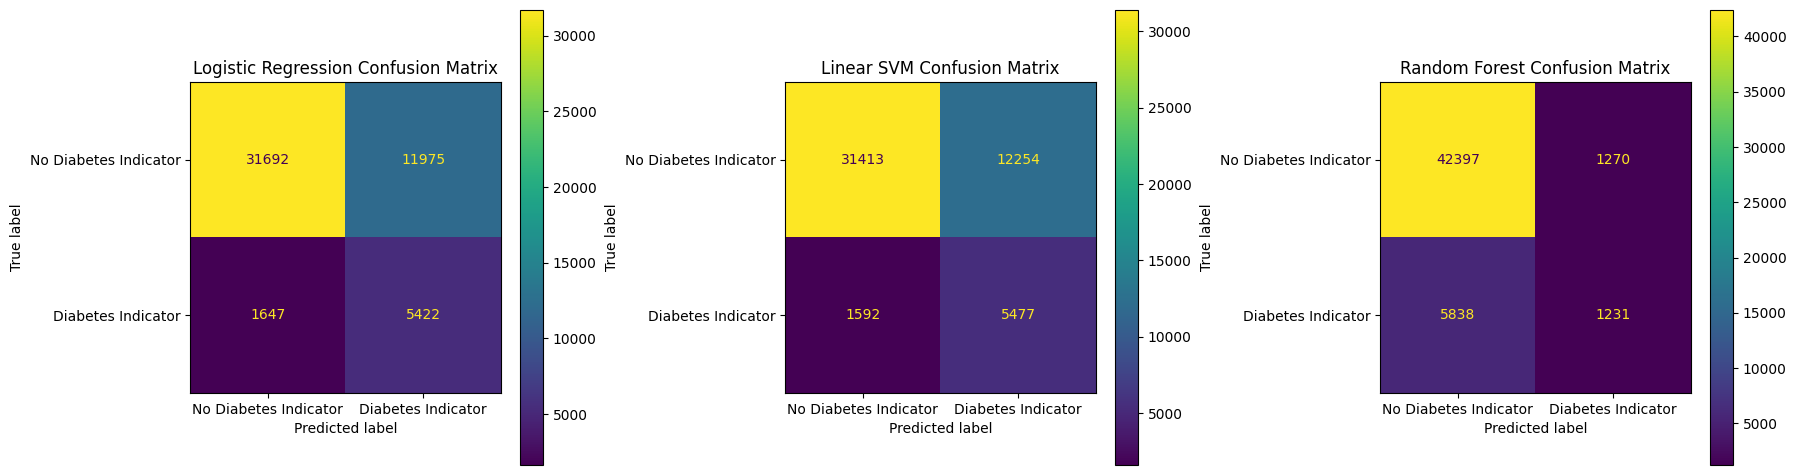

In [126]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(18, 5))
for i, (name, model) in enumerate(trained_models.items()):
  preds = model.predict(X_test)
  ConfusionMatrixDisplay.from_predictions( y_test, preds, display_labels=["No Diabetes Indicator", "Diabetes Indicator"], ax=axes[i])
  axes[i].set_title(f"{name} Confusion Matrix")
plt.tight_layout()
plt.show()

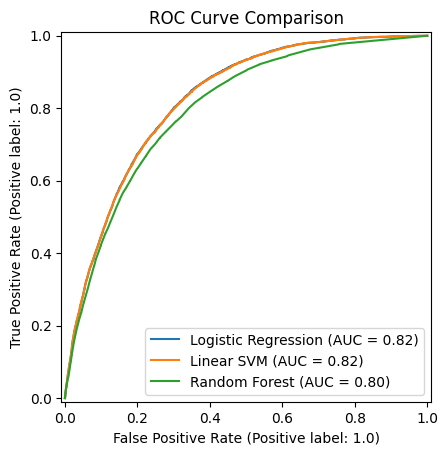

In [127]:
ax = plt.gca() 
for name, model in trained_models.items():
  RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
plt.title("ROC Curve Comparison")
plt.show()


# Phase 6 — Prediction Demo

In [128]:
best_model = trained_models["Random Forest"]
person_1 = {
    "HighBP": 0, "HighChol": 0, "CholCheck": 1,
    "BMI": 22, "Smoker": 0, "Stroke": 0,
    "HeartDiseaseorAttack": 0, "PhysActivity": 1,
    "Fruits": 1, "Veggies": 1, "HvyAlcoholConsump": 0,
    "AnyHealthcare": 1, "NoDocbcCost": 0,
    "GenHlth": 1, "MentHlth": 0, "PhysHlth": 0,
    "DiffWalk": 0, "Sex": 0, "Age": 4,
    "Education": 6, "Income": 8
}
person_2 = {
    "HighBP": 1, "HighChol": 1, "CholCheck": 1,
    "BMI": 35, "Smoker": 1, "Stroke": 0,
    "HeartDiseaseorAttack": 1, "PhysActivity": 0,
    "Fruits": 0, "Veggies": 0, "HvyAlcoholConsump": 0,
    "AnyHealthcare": 1, "NoDocbcCost": 0,
    "GenHlth": 4, "MentHlth": 10, "PhysHlth": 15,
    "DiffWalk": 1, "Sex": 1, "Age": 11,
    "Education": 4, "Income": 3
}
demo_data = pd.DataFrame(
    [person_1, person_2],
    columns=X_train.columns
)
demo_data

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,22,0,0,0,1,1,1,...,1,0,1,0,0,0,0,4,6,8
1,1,1,1,35,1,0,1,0,0,0,...,1,0,4,10,15,1,1,11,4,3


In [129]:
valid_ranges = {
    "BMI": (12, 98),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
    "GenHlth": (1, 5),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8)
}
for column, (minimum, maximum) in valid_ranges.items():
    if not demo_data[column].between(minimum, maximum).all():
        raise ValueError(f"Invalid value in {column}")
binary_features = binary
for column in binary_features:
    if not demo_data[column].isin([0, 1]).all():
        raise ValueError(f"Invalid binary value in {column}")
integer_features = [
    "MentHlth", "PhysHlth", "GenHlth",
    "Age", "Education", "Income"
]
for column in integer_features:
    if not (demo_data[column] % 1 == 0).all():
        raise ValueError(f"{column} must contain whole numbers")
print("All input values are valid!")

All input values are valid!


In [131]:
predictions = best_model.predict(demo_data)
probabilities = best_model.predict_proba(demo_data)[:, 1]
for i in range(len(predictions)):
    print(f"\nExample {i+1}")
    print("Predicted Class:", int(predictions[i]))
    print(
        "Estimated Class Probability:",
        round(probabilities[i] * 100, 2), "%"
    )
    if predictions[i] == 1:
        print("Result: Diabetes Indicator Present")
    else:
        print("Result: No Diabetes Indicator")
    print("---------------------------")


Example 1
Predicted Class: 0
Estimated Class Probability: 0.0 %
Result: No Diabetes Indicator
---------------------------

Example 2
Predicted Class: 1
Estimated Class Probability: 61.0 %
Result: Diabetes Indicator Present
---------------------------


# ============================================================
# Phase 7 — Conclusion & Reflection
# ============================================================

# 1. Project Conclusion
# In this project, I developed a Diabetes Prediction System
# using Machine Learning and the BRFSS 2015 dataset.
#
# The dataset contains 253,680 records and 21 predictor features.
# The target column is Diabetes_binary.
#
# I implemented three Machine Learning algorithms:
# 1. Logistic Regression
# 2. Linear Support Vector Machine (SVM)
# 3. Random Forest Classifier
#
# After comparing the results, Logistic Regression achieved
# the best overall balance between Recall, F1-score and ROC-AUC.


# 2. Model Performance Comparison
#
# Model                 Accuracy   Precision   Recall   F1 Score
# Logistic Regression   73.15%     31.17%       76.70%   44.32%
# Linear SVM            72.71%     30.89%       77.48%   44.17%
# Random Forest         85.99%     49.22%       17.41%   25.73%
#
# Logistic Regression achieved the best F1-score and ROC-AUC.
# Linear SVM achieved slightly higher Recall.
# Random Forest achieved higher Accuracy and Precision but
# had very low Recall.
#
# Therefore, Logistic Regression is the best-balanced model
# based on the evaluation metrics.


# 3. Strongest Patterns Found in the Dataset
#
# - People with high blood pressure showed a higher diabetes
#   indicator rate than people without high blood pressure.
#
# - Higher BMI values were associated with a higher diabetes
#   indicator rate.
#
# - People reporting poorer general health showed higher
#   diabetes indicator rates.
#
# - Diabetes indicator rates generally increased across
#   several older age categories.
#
# These patterns represent associations, not causal relationships.


# 4. Limitations and Ethical Considerations
#
# A. Self-Reporting and Survey Limitations
# - The dataset is based on self-reported survey information.
# - Responses may contain memory errors or incorrect information.
# - BRFSS 2015 data is relatively old and may not represent
#   current health conditions or all populations.
#
# B. Demographic Fairness and Possible Bias
# - Features such as Sex, Age, Education and Income may introduce
#   demographic bias into model predictions.
# - Different demographic groups may receive different results.
# - Further fairness testing is required across these groups.
#
# C. Class Imbalance
# - Class 0 contains approximately 86.07% of the records.
# - Class 1 contains approximately 13.93% of the records.
# - This imbalance can affect model performance.
# - Accuracy alone is not sufficient for model evaluation.
#
# D. Prevalence Shifts and Probability Calibration
# - Diabetes prevalence may differ between populations.
# - Model probabilities may become less reliable when used
#   with a different population.
# - Probability calibration should be evaluated using
#   calibration curves and Brier scores.
#
# E. Lack of External Clinical Validation
# - The model was evaluated using the provided dataset.
# - It has not been validated using an independent clinical dataset.
# - Predictions must not be considered medical diagnoses
#   or used to determine medical treatment.
#
# F. Duplicate Records
# - The dataset contains 24,206 duplicate records.
# - Duplicate records may affect evaluation reliability.
# - Further investigation and duplicate handling are recommended.
#
# G. Data Privacy
# - No identifiable patient data should be collected or uploaded.
# - Only public, hypothetical or synthetic data should be used.
# - Patient privacy and confidentiality must always be protected.


# 5. Future Improvements
#
# 1. Apply class-balancing techniques to improve positive-class Recall.
# 2. Perform hyperparameter tuning for all Machine Learning models.
# 3. Test additional algorithms such as XGBoost and Gradient Boosting.
# 4. Apply SHAP and feature importance for model explainability.
# 5. Evaluate fairness across Sex, Age, Education and Income groups.
# 6. Improve probability calibration and classification thresholds.
# 7. Test the model using newer and independent datasets.


# 6. Final Reflection
#
# This project helped me understand the complete Machine Learning
# workflow, including data preprocessing, EDA, model training,
# model evaluation and prediction.
#
# I learned that high accuracy does not always mean a model
# performs well, especially when working with imbalanced data.
#
# Precision, Recall, F1-score and ROC-AUC are also important
# metrics for evaluating classification models.
#
# Overall, this project demonstrates how Machine Learning can
# identify patterns associated with diabetes indicators.
#
# However, further research, fairness testing and independent
# clinical validation are necessary before real-world application.
#  ******** END ********